# Context Relevance Plots

In [13]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
from pathlib import Path
import logging

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score, roc_auc_score

from experiment_setup.benchmarks import load_examples, sample_tasks
from experiment_setup import dc_pmi, llm_critic
from experiment_setup.logging_setup import logger
from experiment_setup.plots import METRIC_LABELS

CACHE = Path('cache')
MODELS = {
    'Qwen3.5-4B': ('Qwen/Qwen3.5-4B', 'qwen35_4b'),
    'Qwen3.5-9B': ('Qwen/Qwen3.5-9B', 'qwen35_9b'),
    'Qwen3.5-27B': ('Qwen/Qwen3.5-27B', 'qwen35_27b'),
    'Llama3.1-8B': ('meta-llama/Llama-3.1-8B-Instruct', 'llama31_8b'),
    'Llama3.2-3B': ('meta-llama/Llama-3.2-3B-Instruct', 'llama32_3b'),
}


In [15]:
# we kick out that one evil example
examples = [
    example
    for task in load_examples().values()
    for example in task
    if not (
        example.benchmark == "BIG-Bench-Mistake"
        and example.task == "dyck_languages"
        and example.uid == "52"
    )
]
assert len(examples) == 8585 - 1
benchmarks = list(dict.fromkeys(example.benchmark for example in examples))

## Context Relevance

For each context relevance variant, subtract the **average token log likelihood** of a step under the ablated context from the average token log likelihood under the full context. Each average uses the token count in its own context. Perplexity remains based on the full-context average log likelihood. AUROC uses every step, including steps after the annotated first error. Only the first-error step is positive; all other steps are negative. For all three context relevance variants, **lower raw scores** predict first errors (AUROC uses negated scores). Higher perplexity predicts first errors. Each AUROC pools steps within a task type. For context relevance only, one-sided Mann–Whitney U p-values test whether negated scores are higher at first-error steps than at all other steps; bars with p > 0.05 are faded. Perplexity has no significance test.

In [16]:
pmi_stats = []
pmi_scores = []
pooled_pmi_f1 = []
for model, (model_id, stem) in MODELS.items():
    scores = dc_pmi.load_run(
        examples, model_id=model_id, average_ll=True,
        cache_path=CACHE / f'dc_pmi_{stem}_arm.sqlite',
    )
    assert scores[['benchmark', 'task', 'uid']].drop_duplicates().shape[0] == len(examples)
    pmi_scores.append(scores.assign(uid=model + ':' + scores.uid.astype(str)))
    summary = dc_pmi.statistics(scores)
    summary['model'] = model
    pmi_stats.append(summary)
    if model == 'Qwen3.5-27B':
        for benchmark, group in scores.groupby('benchmark', sort=False):
            pooled = dc_pmi.statistics(group.assign(task='(all tasks)'))
            pooled_pmi_f1.append(pooled[['benchmark', 'metric', 'f1']])

pmi_stats = pd.concat(pmi_stats, ignore_index=True)
pooled_pmi_f1 = pd.concat(pooled_pmi_f1, ignore_index=True)
columns = pd.MultiIndex.from_product([MODELS, dc_pmi.METRICS], names=['model', 'metric'])
auc_table = pmi_stats.pivot(index=['benchmark', 'task'], columns=['model', 'metric'], values='auc')
display(auc_table.reindex(columns=columns).round(3))
p_value_table = pmi_stats.pivot(index=['benchmark', 'task'], columns=['model', 'metric'], values='p_value')
display(p_value_table.reindex(columns=columns).round(3))
f1_table = pmi_stats.pivot(index=['benchmark', 'task'], columns=['model', 'metric'], values='f1')
display(f1_table.reindex(columns=columns).round(3))
mcc_table = pmi_stats.pivot(index=['benchmark', 'task'], columns=['model', 'metric'], values='mcc')
display(mcc_table.reindex(columns=columns).round(3))


2026-11-08 08:36:38 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_4b_arm.sqlite
2026-11-08 08:36:46 INFO experiment_setup: Loaded records
2026-11-08 08:37:11 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_9b_arm.sqlite
2026-11-08 08:37:17 INFO experiment_setup: Loaded records
2026-11-08 08:37:41 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_27b_arm.sqlite
2026-11-08 08:37:46 INFO experiment_setup: Loaded records
2026-11-08 08:38:16 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_llama31_8b_arm.sqlite
2026-11-08 08:38:22 INFO experiment_setup: Loaded records
2026-11-08 08:38:42 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_llama32_3b_arm.sqlite
2026-11-08 08:38:48 INFO experiment_setup: Loaded records


model                                       Qwen3.5-4B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.629                 0.585   
                  logical_deduction              0.598                 0.533   
                  multistep_arithmetic           0.522                 0.579   
                  tracking_shuffled_objects      0.559                 0.358   
                  word_sorting                   0.643                 0.588   
MR-GSM8K          POT                            0.687                 0.611   
                  original                       0.561                 0.668   
                  reversed                       0.624                 0.660   
ProcessBench      gsm8k                          0.602                 0.663   
                  math                           0.640                 0.678   
                  olympiadbench                  0.657                 0.693   
                  omnimath                       0.613                 0.692   

model                                                                 \
metric                                      dc_pmi_question_ablation   
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                               0.666   
                  logical_deduction                            0.439   
                  multistep_arithmetic                         0.687   
                  tracking_shuffled_objects                    0.904   
                  word_sorting                                 0.539   
MR-GSM8K          POT                                          0.610   
                  original                                     0.500   
                  reversed                                     0.522   
ProcessBench      gsm8k                                        0.532   
                  math                                         0.527   
                  olympiadbench                                0.618   
                  omnimath                                     0.578   

model                                                                \
metric                                      dc_pmi_history_ablation   
benchmark         task                                                
BIG-Bench-Mistake dyck_languages                              0.558   
                  logical_deduction                           0.558   
                  multistep_arithmetic                        0.510   
                  tracking_shuffled_objects                   0.522   
                  word_sorting                                0.556   
MR-GSM8K          POT                                         0.620   
                  original                                    0.727   
                  reversed                                    0.731   
ProcessBench      gsm8k                                       0.642   
                  math                                        0.676   
                  olympiadbench                               0.674   
                  omnimath                                    0.681   

model                                       Qwen3.5-9B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.645                 0.634   
                  logical_deduction              0.600                 0.530   
                  multistep_arithmetic           0.512                 0.548   
                  tracking_shuffled_objects      0.546                 0.366   
                  word_sorting                   0.669                 0.588   
MR-GSM8K    

model                                       Qwen3.5-4B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                   NaN                 0.000   
                  logical_deduction                NaN                 0.034   
                  multistep_arithmetic             NaN                 0.000   
                  tracking_shuffled_objects        NaN                 1.000   
                  word_sorting                     NaN                 0.000   
MR-GSM8K          POT                              NaN                 0.000   
                  original                         NaN                 0.000   
                  reversed                         NaN                 0.000   
ProcessBench      gsm8k                            NaN                 0.000   
                  math                             NaN                 0.000   
                  olympiadbench                    NaN                 0.000   
                  omnimath                         NaN                 0.000   

model                                                                 \
metric                                      dc_pmi_question_ablation   
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                               0.000   
                  logical_deduction                            1.000   
                  multistep_arithmetic                         0.000   
                  tracking_shuffled_objects                    0.000   
                  word_sorting                                 0.017   
MR-GSM8K          POT                                          0.000   
                  original                                     0.490   
                  reversed                                     0.023   
ProcessBench      gsm8k                                        0.067   
                  math                                         0.015   
                  olympiadbench                                0.000   
                  omnimath                                     0.000   

model                                                                \
metric                                      dc_pmi_history_ablation   
benchmark         task                                                
BIG-Bench-Mistake dyck_languages                              0.000   
                  logical_deduction                           0.001   
                  multistep_arithmetic                        0.317   
                  tracking_shuffled_objects                   0.128   
                  word_sorting                                0.001   
MR-GSM8K          POT                                         0.000   
                  original                                    0.000   
                  reversed                                    0.000   
ProcessBench      gsm8k                                       0.000   
                  math                                        0.000   
                  olympiadbench                               0.000   
                  omnimath                                    0.000   

model                                       Qwen3.5-9B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                   NaN                 0.000   
                  logical_deduction                NaN                 0.046   
                  multistep_arithmetic             NaN                 0.009   
                  tracking_shuffled_objects        NaN                 1.000   
                  word_sorting                     NaN                 0.000   
MR-GSM8K    

model                                       Qwen3.5-4B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.104                 0.071   
                  logical_deduction              0.276                 0.234   
                  multistep_arithmetic           0.324                 0.302   
                  tracking_shuffled_objects      0.407                 0.279   
                  word_sorting                   0.199                 0.185   
MR-GSM8K          POT                            0.172                 0.199   
                  original                       0.162                 0.233   
                  reversed                       0.125                 0.178   
ProcessBench      gsm8k                          0.212                 0.244   
                  math                           0.218                 0.243   
                  olympiadbench                  0.194                 0.212   
                  omnimath                       0.209                 0.254   

model                                                                 \
metric                                      dc_pmi_question_ablation   
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                               0.187   
                  logical_deduction                            0.213   
                  multistep_arithmetic                         0.344   
                  tracking_shuffled_objects                    0.668   
                  word_sorting                                 0.194   
MR-GSM8K          POT                                          0.220   
                  original                                     0.156   
                  reversed                                     0.125   
ProcessBench      gsm8k                                        0.190   
                  math                                         0.175   
                  olympiadbench                                0.183   
                  omnimath                                     0.197   

model                                                                \
metric                                      dc_pmi_history_ablation   
benchmark         task                                                
BIG-Bench-Mistake dyck_languages                              0.065   
                  logical_deduction                           0.237   
                  multistep_arithmetic                        0.308   
                  tracking_shuffled_objects                   0.317   
                  word_sorting                                0.194   
MR-GSM8K          POT                                         0.199   
                  original                                    0.233   
                  reversed                                    0.173   
ProcessBench      gsm8k                                       0.251   
                  math                                        0.248   
                  olympiadbench                               0.213   
                  omnimath                                    0.250   

model                                       Qwen3.5-9B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.105                 0.084   
                  logical_deduction              0.284                 0.224   
                  multistep_arithmetic           0.325                 0.290   
                  tracking_shuffled_objects      0.408                 0.280   
                  word_sorting                   0.211                 0.187   
MR-GSM8K    

model                                       Qwen3.5-4B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.123                 0.068   
                  logical_deduction              0.183                 0.096   
                  multistep_arithmetic           0.200                 0.147   
                  tracking_shuffled_objects      0.325                 0.034   
                  word_sorting                   0.151                 0.102   
MR-GSM8K          POT                            0.079                 0.123   
                  original                       0.109                 0.164   
                  reversed                       0.098                 0.135   
ProcessBench      gsm8k                          0.120                 0.156   
                  math                           0.128                 0.163   
                  olympiadbench                  0.126                 0.165   
                  omnimath                       0.112                 0.174   

model                                                                 \
metric                                      dc_pmi_question_ablation   
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                               0.174   
                  logical_deduction                            0.038   
                  multistep_arithmetic                         0.217   
                  tracking_shuffled_objects                    0.610   
                  word_sorting                                 0.112   
MR-GSM8K          POT                                          0.145   
                  original                                     0.093   
                  reversed                                     0.067   
ProcessBench      gsm8k                                        0.053   
                  math                                         0.042   
                  olympiadbench                                0.108   
                  omnimath                                     0.090   

model                                                                \
metric                                      dc_pmi_history_ablation   
benchmark         task                                                
BIG-Bench-Mistake dyck_languages                              0.045   
                  logical_deduction                           0.104   
                  multistep_arithmetic                        0.130   
                  tracking_shuffled_objects                   0.142   
                  word_sorting                                0.110   
MR-GSM8K          POT                                         0.125   
                  original                                    0.202   
                  reversed                                    0.166   
ProcessBench      gsm8k                                       0.158   
                  math                                        0.175   
                  olympiadbench                               0.170   
                  omnimath                                    0.185   

model                                       Qwen3.5-9B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.131                 0.090   
                  logical_deduction              0.194                 0.081   
                  multistep_arithmetic           0.197                 0.119   
                  tracking_shuffled_objects      0.318                 0.034   
                  word_sorting                   0.204                 0.108   
MR-GSM8K    

In [ ]:
from experiment_setup.plots import plot_task_auc_bars

for metric in dc_pmi.METRICS:
    fig = plot_task_auc_bars(pmi_stats, metric, MODELS)
    fig._suptitle.set_visible(False)
    display(fig)
    plt.close(fig)


## All models: first-error AUROC and significance by benchmark

For each model and benchmark, AUROC pools all steps across task types. The one-sided Mann–Whitney U test asks whether error-evidence scores (higher perplexity or lower context relevance) are higher at annotated first-error steps than at all other steps. Bars with $p \ge 0.05$ are faded; p-values are unadjusted for multiple comparisons.

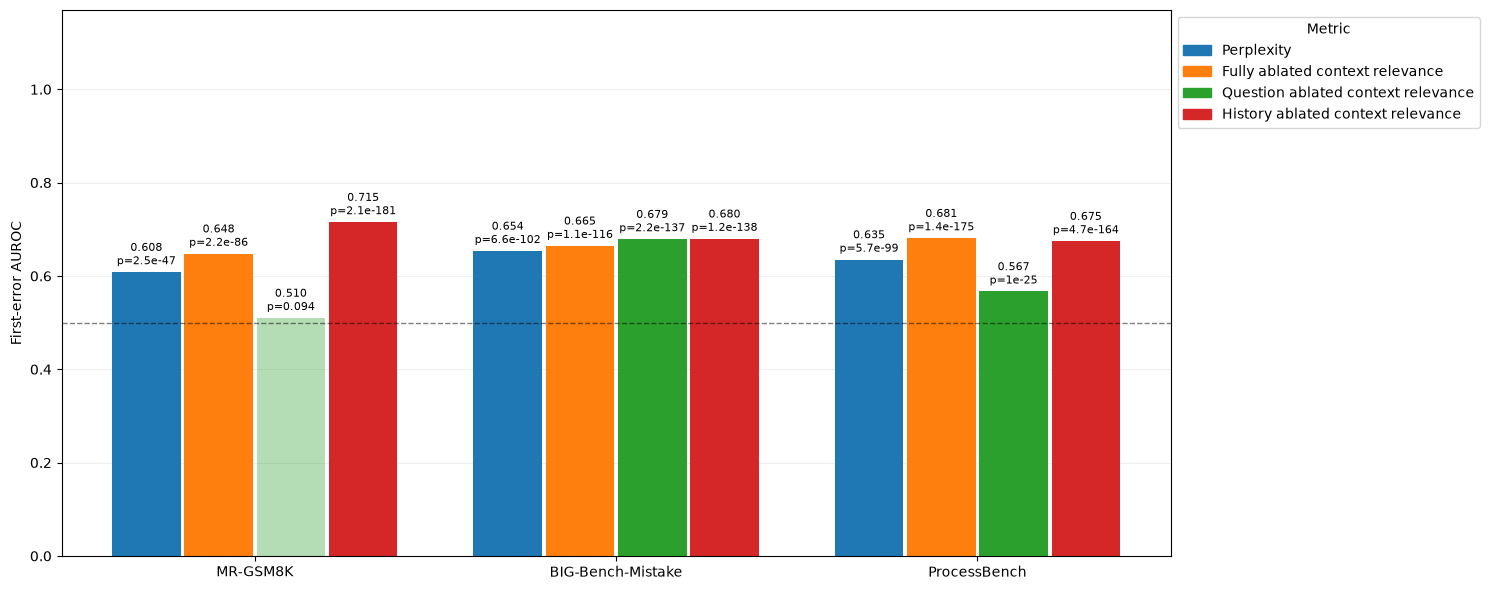

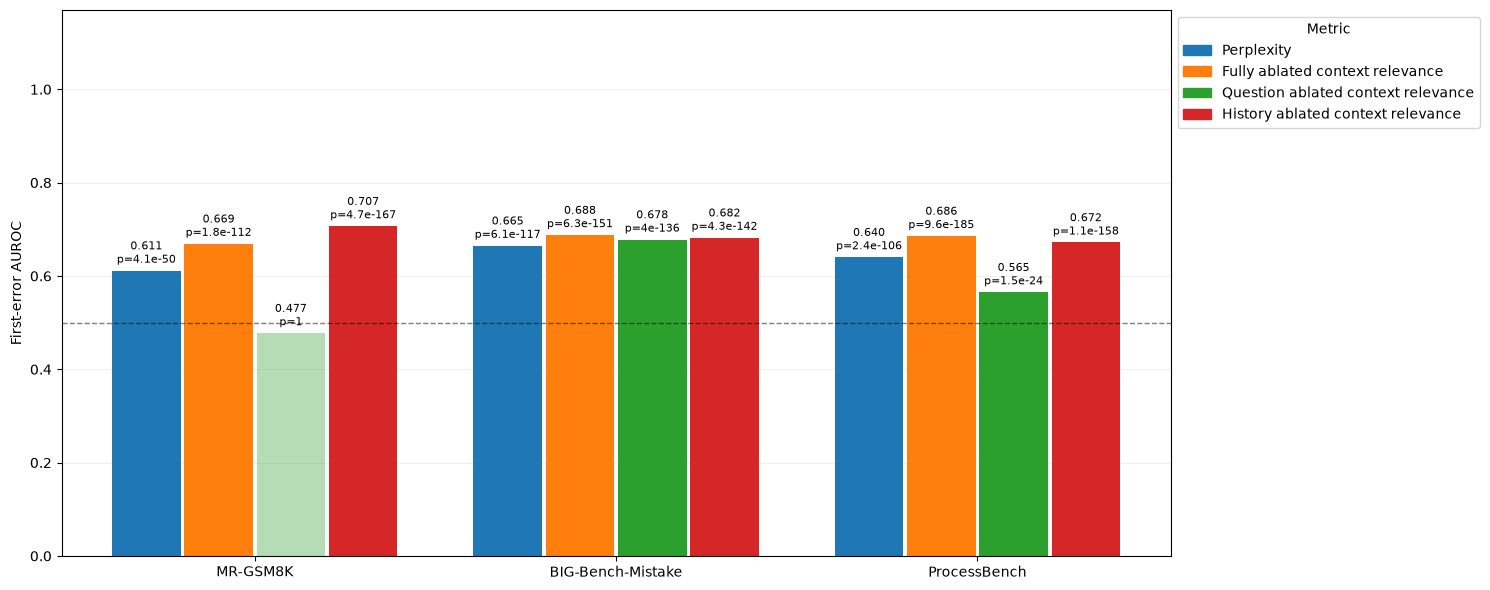

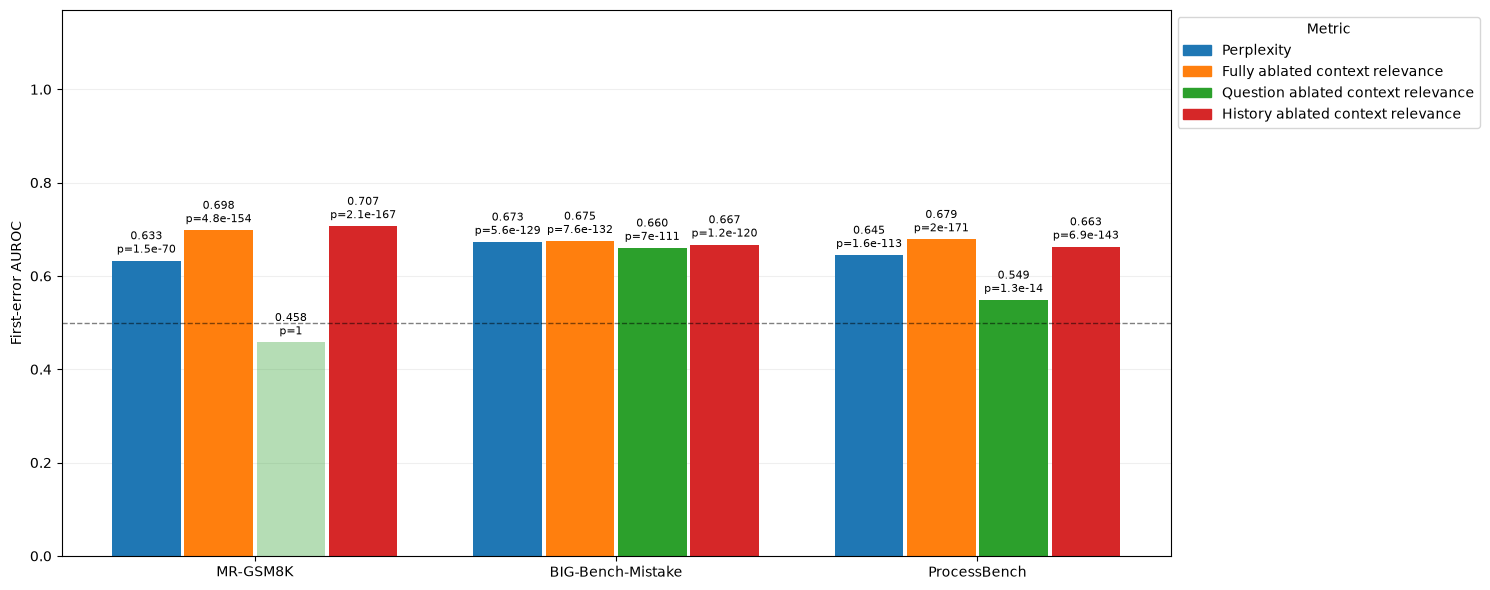

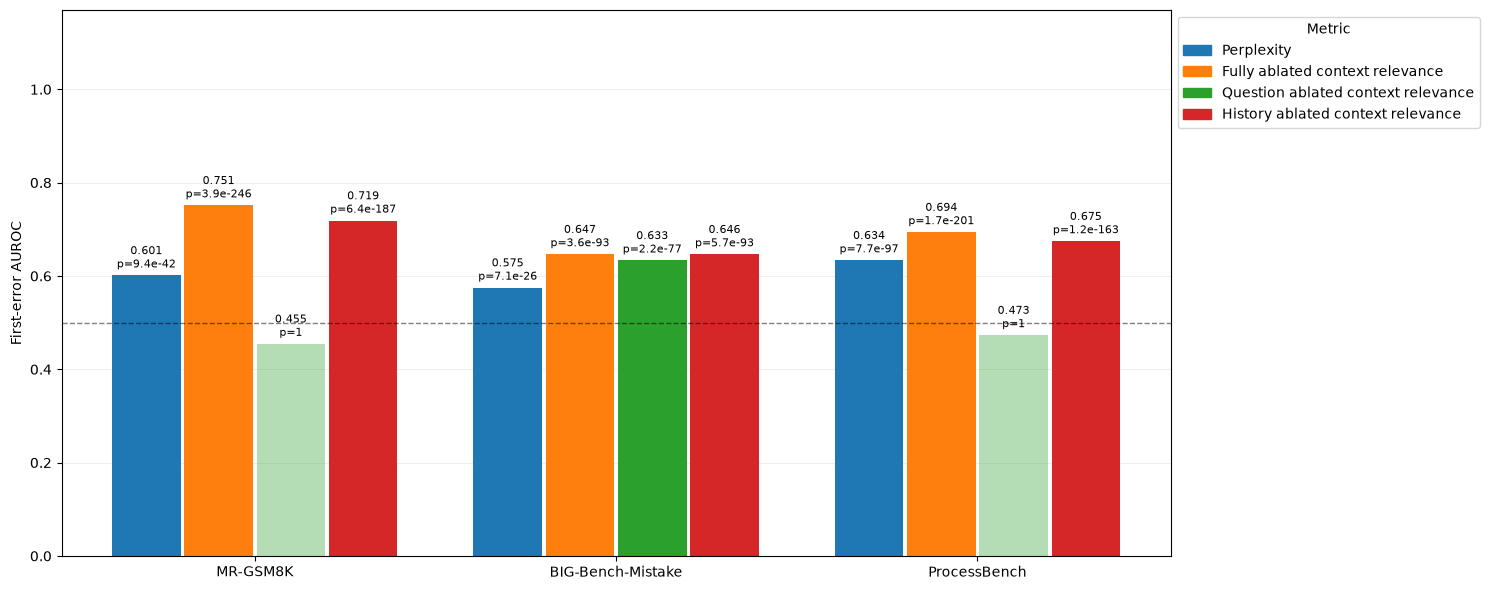

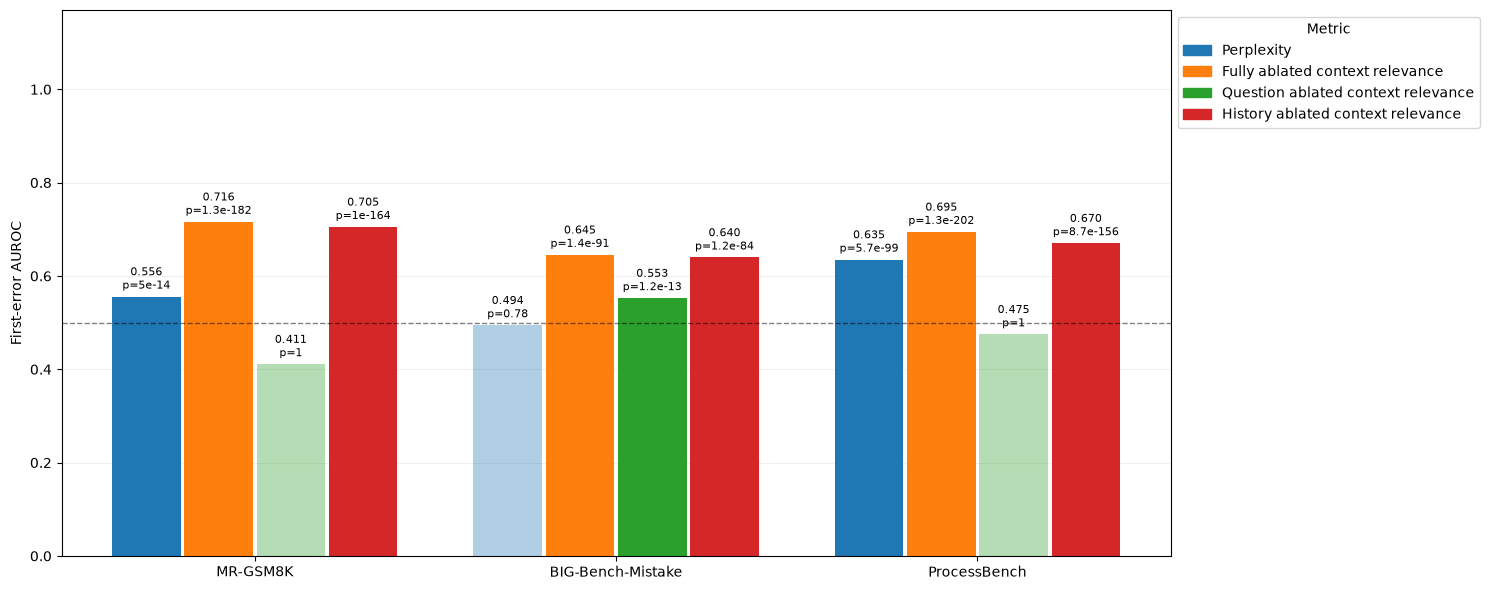

In [18]:
from scipy.stats import mannwhitneyu
from matplotlib.patches import Patch

for model, scores in zip(MODELS, pmi_scores):
    fig, ax = plt.subplots(figsize=(15, 6))
    for benchmark_index, benchmark in enumerate(benchmarks):
        group = scores.loc[scores.benchmark == benchmark]
        assert group.first_error.nunique() == 2
        for metric_index, metric in enumerate(dc_pmi.METRICS):
            evidence = dc_pmi.error_evidence_score(group, metric)
            positives = evidence.loc[group.first_error]
            negatives = evidence.loc[~group.first_error]
            auc = roc_auc_score(group.first_error, evidence)
            p_value = mannwhitneyu(positives, negatives, alternative='greater').pvalue
            x = benchmark_index + (metric_index - (len(dc_pmi.METRICS) - 1) / 2) * 0.2
            bar = ax.bar(x, auc, width=0.19, color=f'C{metric_index}')
            if p_value >= 0.05:
                bar[0].set_alpha(0.35)
            ax.bar_label(bar, labels=[f'{auc:.3f}\np={p_value:.2g}'], padding=3, fontsize=8)
    ax.axhline(0.5, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set(xticks=range(len(benchmarks)), xticklabels=benchmarks,
           ylabel='First-error AUROC', ylim=(0, 1.17))
    ax.legend(handles=[Patch(color=f'C{i}', label=METRIC_LABELS[metric])
                       for i, metric in enumerate(dc_pmi.METRICS)],
              title='Metric', loc='upper left', bbox_to_anchor=(1, 1))
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## Fully ablated context relevance: all models and benchmarks

Each bar pools all steps across task types for one model and benchmark. The one-sided Mann–Whitney U test asks whether negated fully ablated context relevance is higher at annotated first-error steps than at all other steps. Bars with $p \ge 0.05$ are faded; p-values are unadjusted for multiple comparisons.

In [ ]:
# Thesis Figure 6: pooled first-error AUROC for fully ablated context relevance.
from scipy.stats import mannwhitneyu
from matplotlib.patches import Patch

metric = 'dc_pmi_generic_domain'
model_colors = dict(zip(MODELS, ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3']))
fig, ax = plt.subplots(figsize=(14, 6))
bar_width = 0.16
for benchmark_index, benchmark in enumerate(benchmarks):
    for model_index, (model, scores) in enumerate(zip(MODELS, pmi_scores)):
        group = scores.loc[scores.benchmark == benchmark]
        assert group.first_error.nunique() == 2
        evidence = dc_pmi.error_evidence_score(group, metric)
        auc = roc_auc_score(group.first_error, evidence)
        p_value = mannwhitneyu(
            evidence.loc[group.first_error], evidence.loc[~group.first_error],
            alternative='greater',
        ).pvalue
        x = benchmark_index + (model_index - (len(MODELS) - 1) / 2) * bar_width
        bar = ax.bar(x, auc, width=bar_width * 0.9, color=model_colors[model])
        if p_value >= 0.05:
            bar[0].set_alpha(0.35)
        ax.bar_label(bar, labels=[f'{auc:.3f}\np={p_value:.2g}'], padding=3, fontsize=9)
ax.axhline(0.5, color='black', linestyle='--', linewidth=1, alpha=0.5)
ax.set(xticks=range(len(benchmarks)), xticklabels=benchmarks,
       ylabel='First-error AUROC', ylim=(0, 1.17))
ax.set_ylabel('First-error AUROC', fontsize=11)
ax.tick_params(axis='both', labelsize=9)
ax.legend(handles=[Patch(color=model_colors[model], label=model) for model in MODELS],
          loc='upper left', bbox_to_anchor=(1, 1), fontsize=9)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(Path('../thesis/chapters/results/fully-ablated-cr-comparison.png'), dpi=220, bbox_inches='tight')
display(fig)
plt.close(fig)


## Scores around matched error and control positions

Within each benchmark task, each error trace is paired with a distinct error-free trace of the same length; unmatched errors are dropped. Both groups use the error trace's annotated first-error step as step 0. Curves pool all five models and task types with 95% bootstrap confidence intervals across model–trace pairs. The dotted horizontal line marks each group's mean at step 0. Comparing the matched control trajectories with error trajectories helps distinguish error-specific patterns from background variation.

In [20]:
from experiment_setup.benchmarks import sample_control_and_error
from experiment_setup.plots import plot_first_error_trajectories

error_examples, control_examples = sample_control_and_error(examples, seed=42)
assert len(error_examples) == len(control_examples) > 0
assert all((e.benchmark, e.task, len(e.steps)) == (c.benchmark, c.task, len(c.steps))
           for e, c in zip(error_examples, control_examples))
print(f"Sampled n={len(error_examples)} traces contraining errors and n={len(control_examples)} control traces")

Sampled n=2678 traces contraining errors and n=2678 control traces


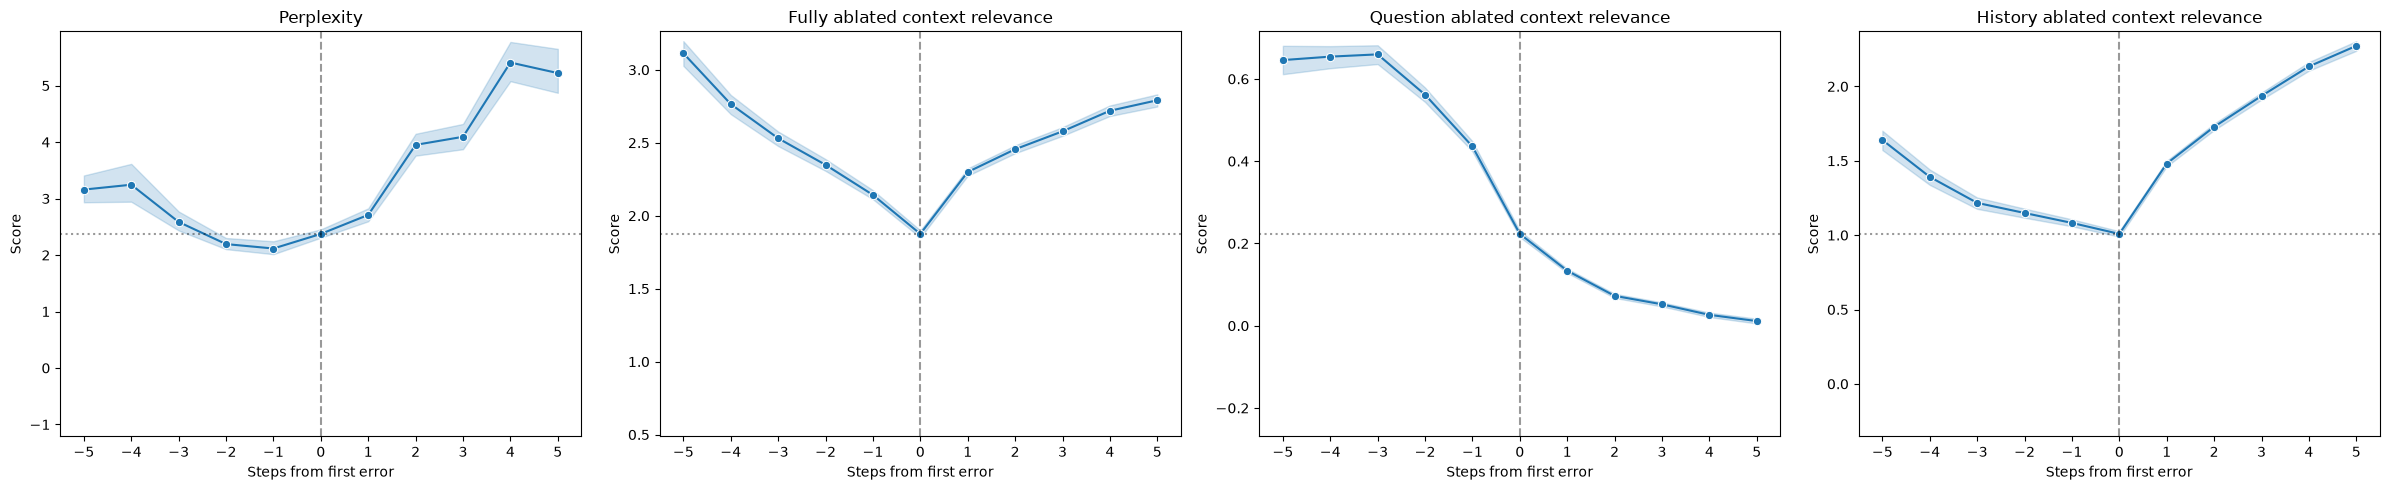

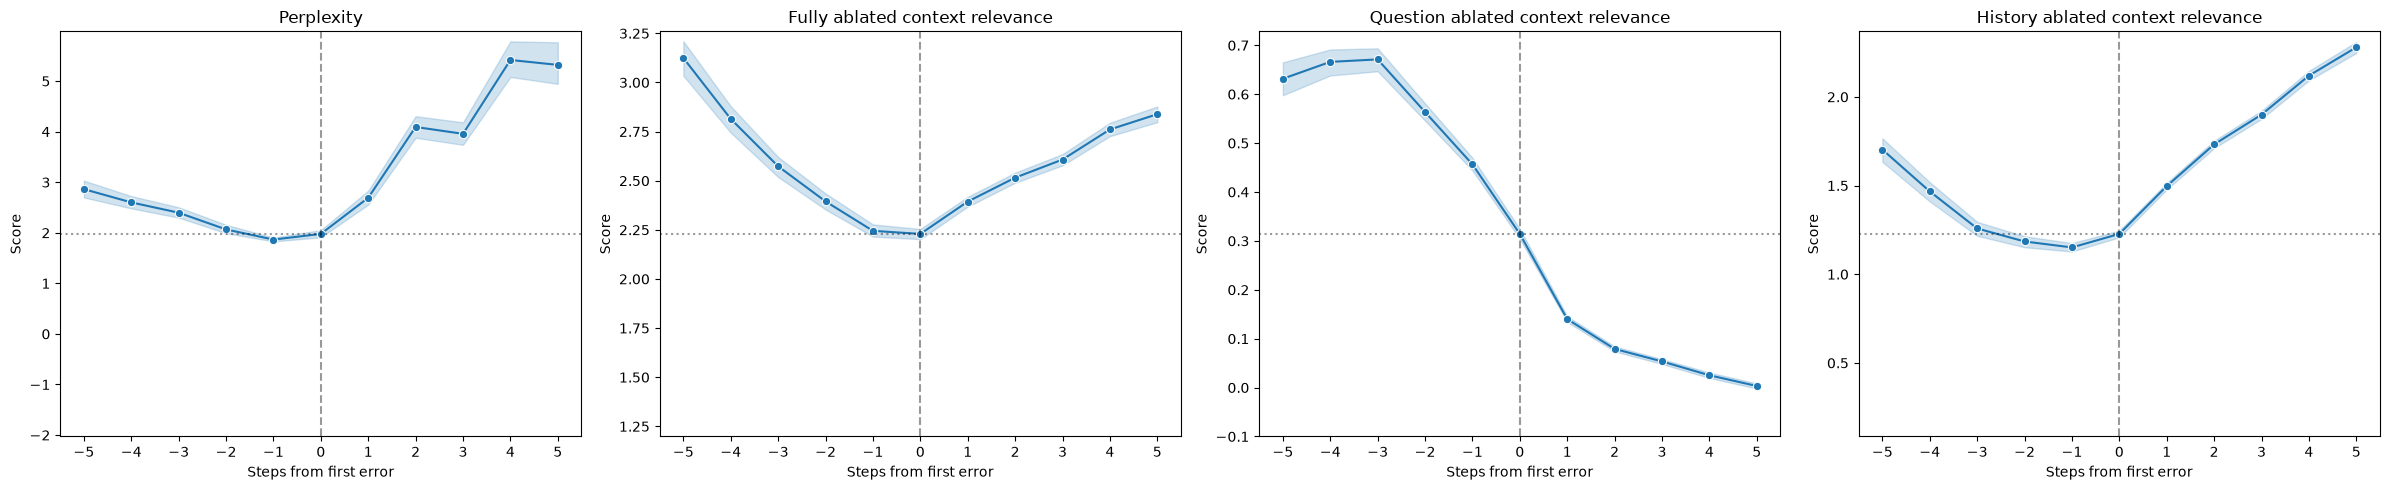

In [21]:
all_scores = pd.concat(pmi_scores, ignore_index=True)
assert all_scores[['benchmark', 'task', 'uid']].drop_duplicates().shape[0] == len(examples) * len(MODELS)
error_keys = pd.DataFrame([
    dict(benchmark=e.benchmark, task=e.task, uid=f'{model}:{e.uid}', n_steps=len(e.steps))
    for e in error_examples for model in MODELS
])
control_anchors = pd.DataFrame([
    dict(benchmark=c.benchmark, task=c.task, uid=f'{model}:{c.uid}',
         anchor=e.label, n_steps=len(c.steps))
    for e, c in zip(error_examples, control_examples) for model in MODELS
])
trace_keys = ['benchmark', 'task', 'uid']
error_scores = all_scores.merge(error_keys, on=trace_keys, how='inner', validate='many_to_one')
control_scores = all_scores.merge(control_anchors, on=trace_keys, how='inner', validate='many_to_one')
assert error_scores[trace_keys].drop_duplicates().shape[0] == len(error_examples) * len(MODELS)
assert control_scores[trace_keys].drop_duplicates().shape[0] == len(control_examples) * len(MODELS)
assert error_scores.groupby(trace_keys).size().eq(error_scores.groupby(trace_keys).n_steps.first()).all()
assert control_scores.groupby(trace_keys).size().eq(control_scores.groupby(trace_keys).n_steps.first()).all()
control_scores['first_error'] = control_scores.step.eq(control_scores.anchor)
assert control_scores.groupby(trace_keys).first_error.sum().eq(1).all()
assert error_scores.groupby(trace_keys).first_error.sum().eq(1).all()

for name, group in [('Error traces', error_scores), ('Matched error-free controls', control_scores)]:
    fig = plot_first_error_trajectories(group)
    display(fig)
    plt.close(fig)


## Scores at matched positions · Qwen3.5-4B

Each histogram compares first-error steps with the corresponding positions in the matched error-free traces, pooled across benchmark tasks. Density normalization makes the distributions comparable.

In [ ]:
from experiment_setup.plots import plot_matched_step_histograms

fig = plot_matched_step_histograms(error_scores, control_scores, model='Qwen3.5-4B')
fig._suptitle.set_visible(False)
fig.tight_layout()
display(fig)
plt.close(fig)


## First differences at matched positions

For each metric, the step-to-step change $y_x - y_{x-1}$ is plotted separately for error traces and their matched error-free controls, using the same aligned positions as above. The first step of a trace has no preceding step, so its difference is missing.

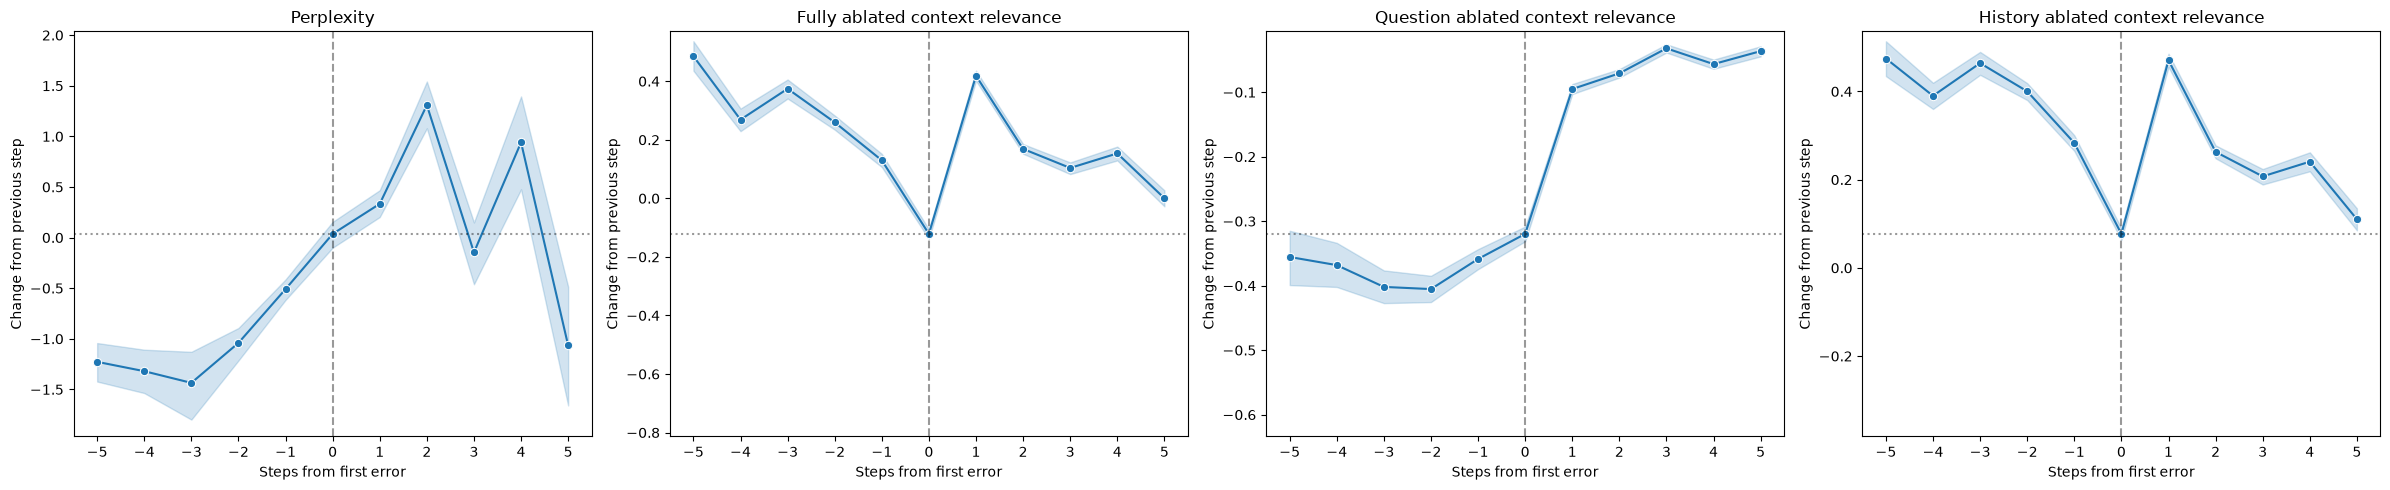

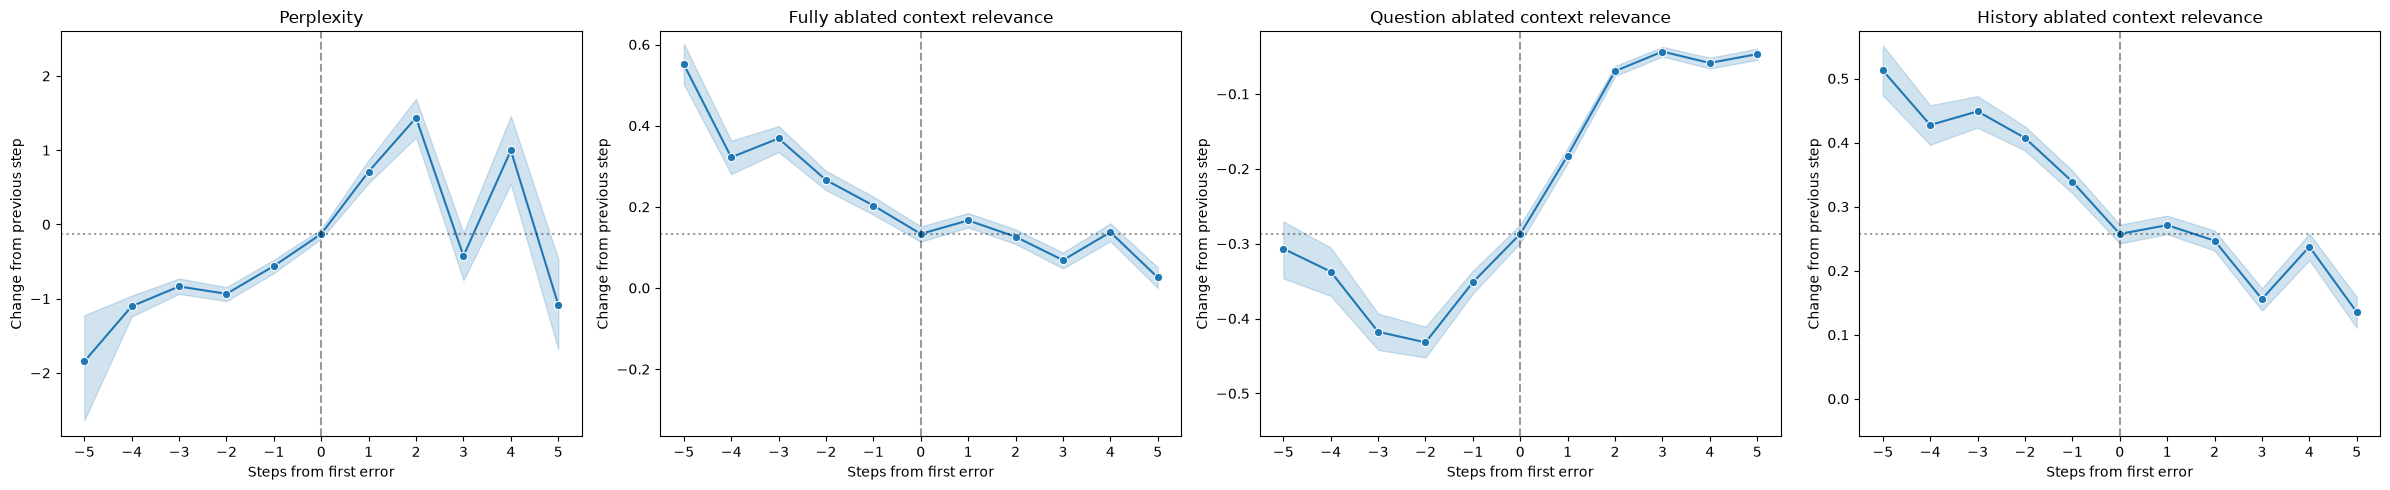

In [23]:
for name, group in [('Error traces', error_scores), ('Matched error-free controls', control_scores)]:
    difference_scores = group.sort_values(trace_keys + ['step']).copy()
    difference_scores[list(dc_pmi.METRICS)] = (
        difference_scores.groupby(trace_keys, sort=False)[list(dc_pmi.METRICS)].diff()
    )
    assert difference_scores.loc[difference_scores.step == 0, list(dc_pmi.METRICS)].isna().all().all()
    fig = plot_first_error_trajectories(difference_scores)
    for ax in fig.axes:
        ax.set_ylabel('Change from previous step')
    display(fig)
    plt.close(fig)


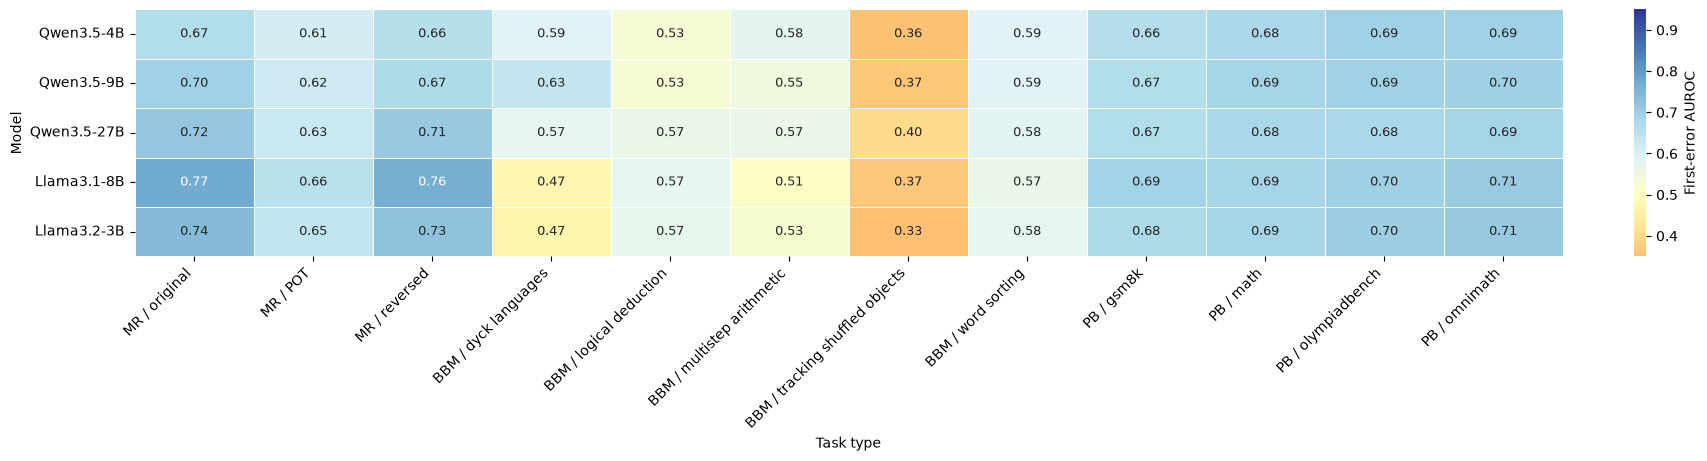

benchmark,MR-GSM8K,BIG-Bench-Mistake,ProcessBench,MR-GSM8K,BIG-Bench-Mistake,ProcessBench,MR-GSM8K,BIG-Bench-Mistake,ProcessBench,MR-GSM8K,BIG-Bench-Mistake,ProcessBench,MR-GSM8K,BIG-Bench-Mistake,ProcessBench
model,Qwen3.5-4B,Qwen3.5-4B,Qwen3.5-4B,Qwen3.5-9B,Qwen3.5-9B,Qwen3.5-9B,Qwen3.5-27B,Qwen3.5-27B,Qwen3.5-27B,Llama3.1-8B,Llama3.1-8B,Llama3.1-8B,Llama3.2-3B,Llama3.2-3B,Llama3.2-3B
method,,,,,,,,,,,,,,,
Fully ablated context relevance,0.648,0.665,0.681,0.669,0.688,0.686,0.698,0.675,0.679,0.751,0.647,0.694,0.716,0.645,0.695
History ablated context relevance,0.715,0.680,0.675,0.707,0.682,0.672,0.707,0.667,0.663,0.719,0.646,0.675,0.705,0.640,0.670
Perplexity,0.608,0.654,0.635,0.611,0.665,0.640,0.633,0.673,0.645,0.601,0.575,0.634,0.556,0.494,0.635
Question ablated context relevance,0.510,0.679,0.567,0.477,0.678,0.565,0.458,0.660,0.549,0.455,0.633,0.473,0.411,0.553,0.475


In [ ]:
# Thesis figure: fully ablated context relevance AUROC by model and task.
import seaborn as sns
out = Path('../thesis/chapters/results')
task_order = list(pmi_stats[['benchmark', 'task']].drop_duplicates().itertuples(index=False, name=None))
labels = [b.replace('BIG-Bench-Mistake', 'BBM').replace('MR-GSM8K', 'MR').replace('ProcessBench', 'PB') + ' / ' + t.replace('_', ' ')
          for b, t in task_order]
subset = pmi_stats.loc[pmi_stats.metric == 'dc_pmi_generic_domain'].copy()
subset['task_label'] = (subset.benchmark.str.replace('BIG-Bench-Mistake', 'BBM', regex=False)
                        .str.replace('MR-GSM8K', 'MR', regex=False)
                        .str.replace('ProcessBench', 'PB', regex=False) + ' / ' + subset.task.str.replace('_', ' '))
grid = subset.pivot(index='model', columns='task_label', values='auc').reindex(index=list(MODELS), columns=labels)
fig, ax = plt.subplots(figsize=(17, 4.5), constrained_layout=True)
sns.heatmap(grid, ax=ax, annot=True, fmt='.2f', cmap='RdYlBu', vmin=0.35, vmax=0.95, center=0.5,
            cbar_kws={'label': 'First-error AUROC'}, linewidths=0.4, annot_kws={'fontsize': 9})
ax.set(xlabel='Task type', ylabel='Model')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
fig.savefig(out / 'task-method-auroc.png', dpi=220, bbox_inches='tight')
plt.show()

# Source values for the benchmark-by-model table in results.typ.
benchmark_rows = []
for model, scores in zip(MODELS, pmi_scores):
    for benchmark in benchmarks:
        group = scores.loc[scores.benchmark == benchmark]
        for metric in dc_pmi.METRICS:
            benchmark_rows.append((METRIC_LABELS[metric], benchmark, model,
                                   roc_auc_score(group.first_error, dc_pmi.error_evidence_score(group, metric))))
benchmark_auroc = pd.DataFrame(benchmark_rows, columns=['method', 'benchmark', 'model', 'auroc'])
display(benchmark_auroc.pivot(index='method', columns=['benchmark', 'model'], values='auroc').round(3))